In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# Find the project data folder
data_file = Path("../data/covid_demo_data.csv")

df = pd.read_csv(data_file)

df["date"] = pd.to_datetime(df["date"])

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (15, 8)


,date,location,population,new_cases,total_cases,new_deaths,total_deaths,people_vaccinated
0,2021-01-01,India,1000000,100,100,2,2,1000
1,2021-01-02,India,1000000,150,250,3,5,2000
2,2021-01-03,India,1000000,200,450,4,9,3000
3,2021-01-04,India,1000000,180,630,3,12,4000
4,2021-01-05,India,1000000,250,880,5,17,5000


In [2]:
# Check missing values
print("Missing values:")
display(df.isnull().sum())


Missing values:


date                 0
location             0
population           0
new_cases            0
total_cases          0
new_deaths           0
total_deaths         0
people_vaccinated    0
dtype: int64

In [3]:
# Summary statistics
display(df.describe())

,date,population,new_cases,total_cases,new_deaths,total_deaths,people_vaccinated
count,15,15.0,15.000000,15.000000,15.000000,15.000000,15.000000
mean,2021-01-03 00:00:00,1000000.0,200.666667,536.666667,4.066667,11.000000,3500.000000
min,2021-01-01 00:00:00,1000000.0,80.000000,80.000000,2.000000,2.000000,500.000000
25%,2021-01-02 00:00:00,1000000.0,155.000000,225.000000,3.000000,5.000000,1750.000000
50%,2021-01-03 00:00:00,1000000.0,200.000000,450.000000,4.000000,9.000000,2500.000000
75%,2021-01-04 00:00:00,1000000.0,250.000000,750.000000,5.000000,16.000000,4500.000000
max,2021-01-05 00:00:00,1000000.0,350.000000,1380.000000,7.000000,27.000000,10000.000000
std,NaN,0.0,75.825614,370.630094,1.437591,7.181325,2738.612788


In [4]:
# Total cases by country in the sample dataset
country_summary = (
    df.groupby("location", as_index=False)
    .agg(
        total_cases=("total_cases", "max"),
        total_deaths=("total_deaths", "max"),
        population=("population", "max"),
    )
)

display(country_summary)

,location,total_cases,total_deaths,population
0,Brazil,750,17,1000000
1,India,880,17,1000000
2,USA,1380,27,1000000


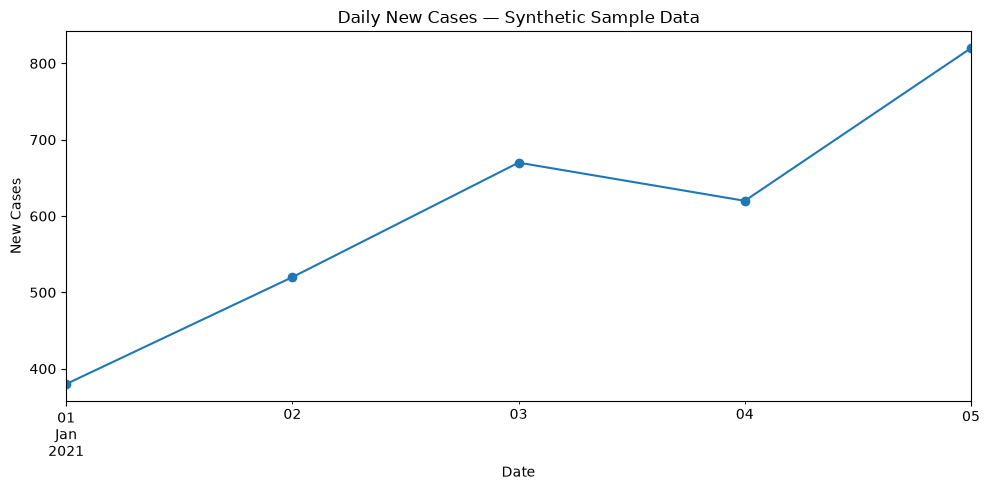

In [5]:
# Visualize the sample data
daily_cases = df.groupby("date")["new_cases"].sum()

daily_cases.plot(
    kind="line",
    figsize=(10, 5),
    marker="o",
    title="Daily New Cases — Synthetic Sample Data",
)

plt.xlabel("Date")
plt.ylabel("New Cases")
plt.tight_layout()
plt.show()